# ITRI625 Cyber Threat Classification

Entity-level NER on the Cyber Threat Dataset.

In [11]:
import sys
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

sys.path.insert(0, str(Path.cwd().parent))
ROOT = Path.cwd().parent

from src.data_loader import load_datasets
from src.preprocess import extract_entity_examples, encode_labels, prepare_text_data
from src.model import build_model

print('Setup complete.')

Setup complete.


In [12]:
_, _, raw_test = load_datasets(ROOT / 'data')
test_examples = extract_entity_examples(raw_test)
print(f'Test examples: {len(test_examples)}')
print(f'Unique labels: {len(set(e["label"] for e in test_examples))}')

Test examples: 1843
Unique labels: 20


In [13]:
with open(ROOT / 'models' / 'label_encoder.pkl', 'rb') as f:
    encoder = pickle.load(f)
with open(ROOT / 'models' / 'tokenizer.pkl', 'rb') as f:
    vocabulary = pickle.load(f)

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=10000, output_mode='int', output_sequence_length=50,
    standardize='lower_and_strip_punctuation',
)
vectorizer.set_vocabulary(vocabulary)

model = build_model(vectorizer, num_classes=len(encoder.classes_))
model.load_weights(ROOT / 'models' / 'best_model.h5')
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print('Model loaded.')

Model loaded.


c:\Users\tsheg\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\layer.py:1039: UserWarning: Layer 'attention' (of type AttentionLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


In [14]:
texts = prepare_text_data(test_examples)
labels = encode_labels(test_examples, encoder)

ds = tf.data.Dataset.from_tensor_slices(tf.constant(texts, dtype=tf.string)).batch(32)
probs = model.predict(ds, verbose=0)
pred = probs.argmax(axis=1)
names = encoder.classes_.tolist()

report = classification_report(labels, pred, labels=list(range(len(names))), target_names=names, output_dict=True, zero_division=0)
print(f'Accuracy: {report["accuracy"]:.4f}')
print(f'Macro F1: {report["macro avg"]["f1-score"]:.4f}')

c:\Users\tsheg\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\layer.py:1039: UserWarning: Layer 'attention' (of type AttentionLayer) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Accuracy: 0.7189
Macro F1: 0.5244


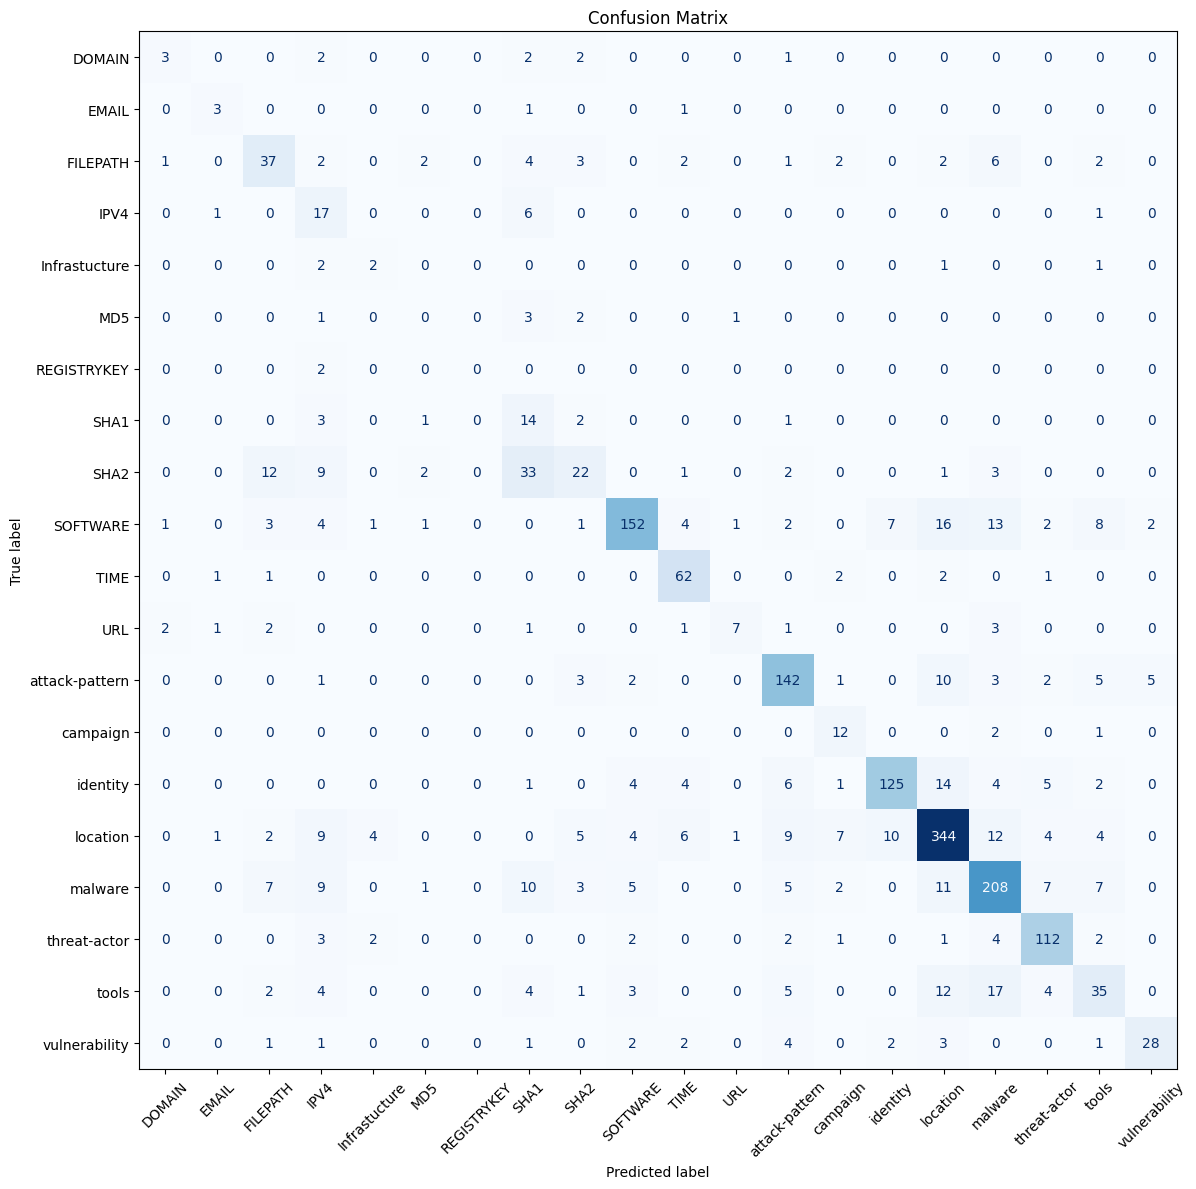

In [15]:
fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(labels, pred, display_labels=names, xticks_rotation=45, cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()